Q1

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(r"C:\Users\Administrator\Downloads\student_tea_snacks.csv")
print(df.head())

  student_id gender age_group prefers_tea     tea_type snack_choice  \
0       S001   Male     21-23          No        Black       Samosa   
1       S002   Male     21-23          No        Green       Samosa   
2       S003   Male     18-20          No  Doodh Patti      Biscuit   
3       S004   Male     21-23         Yes          NaN       Samosa   
4       S005   Male     18-20         Yes        Green       Samosa   

   cups_per_day  
0             2  
1             3  
2             0  
3             1  
4             4  


In [2]:
tea_counts = df["tea_type"].value_counts()
print(tea_counts)
print(
    f"\nMost preferred tea type: {tea_counts.index[0]}"
    f" ({tea_counts.iloc[0]} students)"
)

tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64

Most preferred tea type: Green (29 students)


Q2

In [4]:
avg_cups_gender = df.groupby("gender")["cups_per_day"].agg(
    count="count", mean="mean", median="median", min="min", max="max", std="std")
print(avg_cups_gender.round(2))

        count  mean  median  min  max   std
gender                                     
Female     47   2.6     3.0    0    5  1.75
Male       53   3.0     3.0    0    5  1.59


Q3

snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


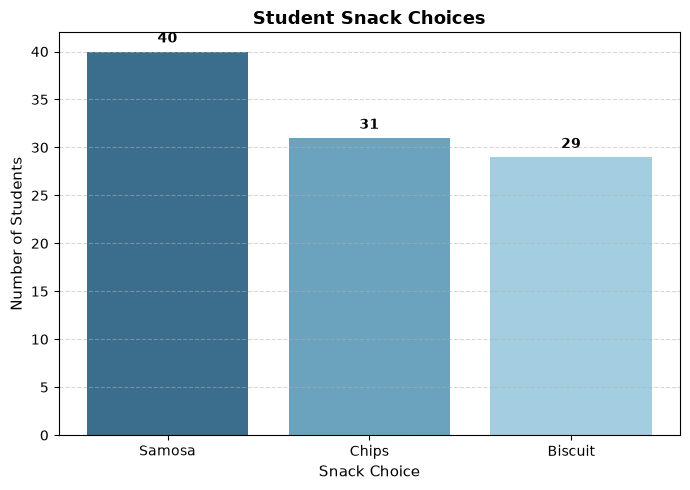

In [5]:
snack_counts = df["snack_choice"].value_counts()
print(snack_counts)

plt.figure(figsize=(7, 5))
bars = plt.bar(
    snack_counts.index,
    snack_counts.values,
    color=["#3b6e8c", "#6ba3be", "#a3cde0"],
)
plt.title("Student Snack Choices", fontsize=13, fontweight="bold")
plt.xlabel("Snack Choice", fontsize=11)
plt.ylabel("Number of Students", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      height + 0.6,
      f"{int(height)}",
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

Q4

In [6]:
# Compare 'prefers_tea' across age groups
print("Tea Preference ('prefers_tea') by Age Group:")
print(pd.crosstab(df["age_group"], df["prefers_tea"], margins=True))

# Compare 'tea_type' across age groups
print("\nTea Type ('tea_type') by Age Group:")
print(
    pd.crosstab(df["age_group"], df["tea_type"].fillna("Missing"), margins=True))

Tea Preference ('prefers_tea') by Age Group:
prefers_tea  No  Yes  All
age_group                
18-20        19   20   39
21-23        17   15   32
24-26        13   16   29
All          49   51  100

Tea Type ('tea_type') by Age Group:
tea_type   Black  Doodh Patti  Green  Missing  All
age_group                                         
18-20          9           11     13        6   39
21-23          9            6      5       12   32
24-26          5            8     11        5   29
All           23           25     29       23  100


Q5

In [7]:
no_pref_count = (df["prefers_tea"] == "No").sum()
zero_cups_count = (df["cups_per_day"] == 0).sum()

print(f"Students with prefers_tea == 'No': {no_pref_count}")
print(f"Students with cups_per_day == 0: {zero_cups_count}")

Students with prefers_tea == 'No': 49
Students with cups_per_day == 0: 13
